# 07 — Engineering Monitoring Recommendations

## Objective

This notebook translates the predictive-model and key-signal results into
a retrospective engineering-monitoring prototype.

The objectives are:

1. convert out-of-fold risk scores into investigation-priority levels;
2. quantify the trade-off between investigation workload, detected Fail
   samples, and false alarms;
3. attach stable candidate signals to high-risk samples as investigation
   context;
4. define a shadow-mode monitoring workflow;
5. specify the data-quality, alert-volume, and model-performance indicators
   that should be monitored over time.

The proposed system is a decision-support and investigation-prioritization
tool. It is not an automatic product-disposition system and does not
identify confirmed physical root causes.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

## 7.1 Recreate Out-of-Fold Risk Scores

The Random Forest out-of-fold risk scores are recreated using the same
stratified ten-fold design and model configuration used in the previous
chapters.

Each sample receives a score from a model that was not trained on that
sample. These out-of-fold scores provide a leakage-safe retrospective
approximation of how the model would prioritize previously unseen
samples.

The scores are used for monitoring-policy evaluation rather than being
interpreted as perfectly calibrated failure probabilities.

In [2]:
data_dir = Path("../data/raw")

feature_path = data_dir / "secom.data"
label_path = data_dir / "secom_labels.data"

X = pd.read_csv(
    feature_path,
    sep=r"\s+",
    header=None
)

X.columns = [
    f"feature_{column_number}"
    for column_number in range(X.shape[1])
]

labels = pd.read_csv(
    label_path,
    sep=r"\s+",
    header=None,
    names=[
        "original_label",
        "timestamp_text"
    ]
)

y = (
    labels["original_label"] == 1
).astype(int)

timestamps = pd.to_datetime(
    labels["timestamp_text"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

In [3]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass counts:")
print(y.value_counts().sort_index())

print(
    "\nParsed timestamps:",
    timestamps.notna().sum()
)

print(
    "Timestamp range:",
    timestamps.min(),
    "to",
    timestamps.max()
)

assert len(X) == len(y)
assert len(timestamps) == len(y)
assert set(y.unique()) == {0, 1}

X shape: (1567, 590)
y shape: (1567,)

Class counts:
original_label
0    1463
1     104
Name: count, dtype: int64

Parsed timestamps: 1567
Timestamp range: 2008-07-19 11:55:00 to 2008-10-17 06:07:00


In [4]:
random_forest_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "remove_constants",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=3,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

In [5]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

In [6]:
random_forest_oof_scores = np.full(
    len(y),
    np.nan
)

oof_fold_number = np.full(
    len(y),
    np.nan
)

In [7]:
for fold_number, (
    train_index,
    validation_index
) in enumerate(
    cv.split(X, y),
    start=1
):

    X_train_fold = X.iloc[
        train_index
    ]

    X_validation_fold = X.iloc[
        validation_index
    ]

    y_train_fold = y.iloc[
        train_index
    ]

    fold_model = clone(
        random_forest_pipeline
    )

    fold_model.fit(
        X_train_fold,
        y_train_fold
    )

    validation_scores = (
        fold_model.predict_proba(
            X_validation_fold
        )[:, 1]
    )

    random_forest_oof_scores[
        validation_index
    ] = validation_scores

    oof_fold_number[
        validation_index
    ] = fold_number

    print(
        f"Fold {fold_number}: "
        f"{len(validation_index)} scores generated"
    )

Fold 1: 157 scores generated
Fold 2: 157 scores generated
Fold 3: 157 scores generated
Fold 4: 157 scores generated
Fold 5: 157 scores generated
Fold 6: 157 scores generated
Fold 7: 157 scores generated
Fold 8: 156 scores generated
Fold 9: 156 scores generated
Fold 10: 156 scores generated


In [8]:
assert not np.isnan(
    random_forest_oof_scores
).any()

assert not np.isnan(
    oof_fold_number
).any()

print(
    "OOF score count:",
    len(random_forest_oof_scores)
)

print(
    "OOF score range:",
    random_forest_oof_scores.min(),
    "to",
    random_forest_oof_scores.max()
)

OOF score count: 1567
OOF score range: 0.0634468453583391 to 0.47065448791974623


In [9]:
random_forest_oof_ap = (
    average_precision_score(
        y,
        random_forest_oof_scores
    )
)

random_forest_oof_roc_auc = (
    roc_auc_score(
        y,
        random_forest_oof_scores
    )
)

print(
    "Random Forest OOF Average Precision:",
    round(
        random_forest_oof_ap,
        4
    )
)

print(
    "Random Forest OOF ROC-AUC:",
    round(
        random_forest_oof_roc_auc,
        4
    )
)

Random Forest OOF Average Precision: 0.1627
Random Forest OOF ROC-AUC: 0.7457


In [10]:
monitoring_data = pd.DataFrame({
    "sample_id": np.arange(
        len(X)
    ),
    "timestamp": timestamps,
    "actual_outcome": np.where(
        y == 1,
        "Fail",
        "Pass"
    ),
    "actual_label": y,
    "oof_risk_score": (
        random_forest_oof_scores
    ),
    "oof_fold": (
        oof_fold_number.astype(int)
    )
})

In [11]:
monitoring_data[
    "risk_rank"
] = (
    monitoring_data[
        "oof_risk_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

In [12]:
monitoring_data[
    "risk_percentile"
] = (
    monitoring_data[
        "oof_risk_score"
    ]
    .rank(
        method="average",
        pct=True
    )
)

In [13]:
monitoring_data.sort_values(
    "oof_risk_score",
    ascending=False
).head(20)

,sample_id,timestamp,actual_outcome,actual_label,oof_risk_score,oof_fold,risk_rank,risk_percentile
34,34,2008-07-28 03:31:00,Pass,0,0.470654,5,1,1.000000
47,47,2008-07-29 15:41:00,Pass,0,0.468713,3,2,0.999362
161,161,2008-08-08 21:53:00,Pass,0,0.458976,7,3,0.998724
44,44,2008-07-29 06:19:00,Pass,0,0.458975,8,4,0.998086
186,186,2008-08-10 15:59:00,Fail,1,0.456670,3,5,0.997447
55,55,2008-07-30 07:08:00,Pass,0,0.449039,10,6,0.996809
207,207,2008-08-15 18:19:00,Pass,0,0.448969,6,7,0.996171
209,209,2008-08-15 20:00:00,Pass,0,0.445976,5,8,0.995533
159,159,2008-08-08 20:21:00,Pass,0,0.437200,6,9,0.994895
14,14,2008-07-21 11:53:00,Fail,1,0.434757,7,10,0.994257


In [14]:
investigation_budgets = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30
]

budget_rows = []

for budget in investigation_budgets:

    score_threshold = np.quantile(
        random_forest_oof_scores,
        1 - budget
    )

    alerts = (
        random_forest_oof_scores
        >= score_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        alerts,
        labels=[0, 1]
    ).ravel()

    alert_count = (
        alerts.sum()
    )

    actual_alert_rate = (
        alert_count
        / len(y)
    )

    fail_recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    alert_precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    false_alarm_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    false_alarms_per_detected_fail = (
        fp / tp
        if tp > 0
        else np.nan
    )

    investigations_per_detected_fail = (
        alert_count / tp
        if tp > 0
        else np.nan
    )

    precision_lift = (
        alert_precision / y.mean()
        if y.mean() > 0
        else np.nan
    )

    budget_rows.append({
        "target_budget": budget,
        "score_threshold": score_threshold,
        "alert_count": alert_count,
        "actual_alert_rate": actual_alert_rate,
        "detected_fails_tp": tp,
        "missed_fails_fn": fn,
        "false_alarms_fp": fp,
        "correct_non_alerts_tn": tn,
        "fail_recall": fail_recall,
        "alert_precision": alert_precision,
        "false_alarm_rate": false_alarm_rate,
        "false_alarms_per_detected_fail": (
            false_alarms_per_detected_fail
        ),
        "investigations_per_detected_fail": (
            investigations_per_detected_fail
        ),
        "precision_lift_over_baseline": (
            precision_lift
        )
    })

investigation_budget_table = pd.DataFrame(
    budget_rows
)

In [15]:
investigation_budget_display = (
    investigation_budget_table.copy()
)

percentage_columns = [
    "target_budget",
    "actual_alert_rate",
    "fail_recall",
    "alert_precision",
    "false_alarm_rate"
]

investigation_budget_display[
    percentage_columns
] = (
    investigation_budget_display[
        percentage_columns
    ] * 100
)

investigation_budget_display.round({
    "target_budget": 1,
    "score_threshold": 4,
    "actual_alert_rate": 1,
    "fail_recall": 1,
    "alert_precision": 1,
    "false_alarm_rate": 1,
    "false_alarms_per_detected_fail": 2,
    "investigations_per_detected_fail": 2,
    "precision_lift_over_baseline": 2
})

,target_budget,score_threshold,alert_count,actual_alert_rate,detected_fails_tp,missed_fails_fn,false_alarms_fp,correct_non_alerts_tn,fail_recall,alert_precision,false_alarm_rate,false_alarms_per_detected_fail,investigations_per_detected_fail,precision_lift_over_baseline
0,5.0,0.3541,79,5.0,18,86,61,1402,17.3,22.8,4.2,3.39,4.39,3.43
1,10.0,0.3147,157,10.0,32,72,125,1338,30.8,20.4,8.5,3.91,4.91,3.07
2,15.0,0.2868,235,15.0,43,61,192,1271,41.3,18.3,13.1,4.47,5.47,2.76
3,20.0,0.2669,314,20.0,53,51,261,1202,51.0,16.9,17.8,4.92,5.92,2.54
4,25.0,0.2503,392,25.0,62,42,330,1133,59.6,15.8,22.6,5.32,6.32,2.38
5,30.0,0.2372,470,30.0,67,37,403,1060,64.4,14.3,27.5,6.01,7.01,2.15


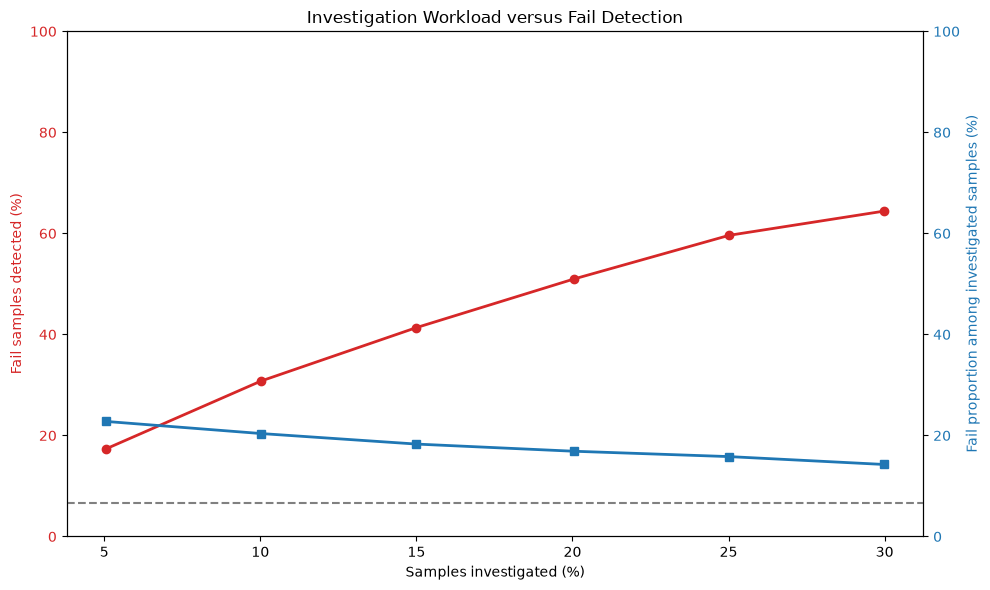

In [16]:
fig, ax1 = plt.subplots(
    figsize=(10, 6)
)

ax1.plot(
    investigation_budget_table[
        "actual_alert_rate"
    ] * 100,
    investigation_budget_table[
        "fail_recall"
    ] * 100,
    marker="o",
    linewidth=2,
    color="#D62728",
    label="Fail recall"
)

ax1.set_xlabel(
    "Samples investigated (%)"
)

ax1.set_ylabel(
    "Fail samples detected (%)",
    color="#D62728"
)

ax1.tick_params(
    axis="y",
    labelcolor="#D62728"
)

ax1.set_ylim(0, 100)

ax2 = ax1.twinx()

ax2.plot(
    investigation_budget_table[
        "actual_alert_rate"
    ] * 100,
    investigation_budget_table[
        "alert_precision"
    ] * 100,
    marker="s",
    linewidth=2,
    color="#1F77B4",
    label="Alert precision"
)

ax2.axhline(
    y.mean() * 100,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Baseline Fail rate"
)

ax2.set_ylabel(
    "Fail proportion among investigated samples (%)",
    color="#1F77B4"
)

ax2.tick_params(
    axis="y",
    labelcolor="#1F77B4"
)

ax2.set_ylim(0, 100)

plt.title(
    "Investigation Workload versus Fail Detection"
)

fig.tight_layout()
plt.show()

## 7.10 Define Risk-Based Investigation Tiers

A three-level investigation queue is created as a retrospective monitoring
prototype:

- **Red:** highest-risk 5% of samples, prioritized for immediate
  engineering review;
- **Amber:** samples between the highest-risk 5% and 20%, reviewed when
  additional investigation capacity is available;
- **Routine:** remaining samples, which continue through existing
  production and quality-control procedures.

The Routine tier does not indicate that a sample is guaranteed to Pass.
The model is used to add investigation priority rather than replace
existing product-disposition or quality-control rules.

In [17]:
red_threshold = (
    investigation_budget_table
    .loc[
        investigation_budget_table[
            "target_budget"
        ] == 0.05,
        "score_threshold"
    ]
    .iloc[0]
)

amber_threshold = (
    investigation_budget_table
    .loc[
        investigation_budget_table[
            "target_budget"
        ] == 0.20,
        "score_threshold"
    ]
    .iloc[0]
)

print(
    "Red threshold:",
    round(red_threshold, 4)
)

print(
    "Amber threshold:",
    round(amber_threshold, 4)
)

Red threshold: 0.3541
Amber threshold: 0.2669


In [18]:
monitoring_data[
    "risk_tier"
] = np.select(
    [
        monitoring_data[
            "oof_risk_score"
        ] >= red_threshold,

        monitoring_data[
            "oof_risk_score"
        ] >= amber_threshold
    ],
    [
        "Red",
        "Amber"
    ],
    default="Routine"
)

In [19]:
monitoring_data[
    "risk_tier"
] = pd.Categorical(
    monitoring_data[
        "risk_tier"
    ],
    categories=[
        "Red",
        "Amber",
        "Routine"
    ],
    ordered=True
)

In [20]:
risk_tier_summary = (
    monitoring_data
    .groupby(
        "risk_tier",
        observed=False
    )
    .agg(
        sample_count=(
            "sample_id",
            "count"
        ),
        fail_count=(
            "actual_label",
            "sum"
        ),
        mean_risk_score=(
            "oof_risk_score",
            "mean"
        ),
        median_risk_score=(
            "oof_risk_score",
            "median"
        ),
        minimum_risk_score=(
            "oof_risk_score",
            "min"
        ),
        maximum_risk_score=(
            "oof_risk_score",
            "max"
        )
    )
    .reset_index()
)

In [21]:
risk_tier_summary[
    "pass_count"
] = (
    risk_tier_summary[
        "sample_count"
    ]
    - risk_tier_summary[
        "fail_count"
    ]
)

risk_tier_summary[
    "workload_share"
] = (
    risk_tier_summary[
        "sample_count"
    ]
    / len(monitoring_data)
)

risk_tier_summary[
    "tier_fail_rate"
] = (
    risk_tier_summary[
        "fail_count"
    ]
    / risk_tier_summary[
        "sample_count"
    ]
)

risk_tier_summary[
    "share_of_all_fails"
] = (
    risk_tier_summary[
        "fail_count"
    ]
    / y.sum()
)

risk_tier_summary[
    "lift_over_baseline"
] = (
    risk_tier_summary[
        "tier_fail_rate"
    ]
    / y.mean()
)

In [22]:
risk_tier_display = (
    risk_tier_summary.copy()
)

percentage_columns = [
    "workload_share",
    "tier_fail_rate",
    "share_of_all_fails"
]

risk_tier_display[
    percentage_columns
] = (
    risk_tier_display[
        percentage_columns
    ] * 100
)

risk_tier_display.round({
    "mean_risk_score": 4,
    "median_risk_score": 4,
    "minimum_risk_score": 4,
    "maximum_risk_score": 4,
    "workload_share": 1,
    "tier_fail_rate": 1,
    "share_of_all_fails": 1,
    "lift_over_baseline": 2
})

,risk_tier,sample_count,fail_count,mean_risk_score,median_risk_score,minimum_risk_score,maximum_risk_score,pass_count,workload_share,tier_fail_rate,share_of_all_fails,lift_over_baseline
0,Red,79,18,0.3934,0.3853,0.3547,0.4707,61,5.0,22.8,17.3,3.43
1,Amber,235,35,0.3032,0.3019,0.2669,0.3526,200,15.0,14.9,33.7,2.24
2,Routine,1253,51,0.1769,0.1768,0.0634,0.2668,1202,80.0,4.1,49.0,0.61


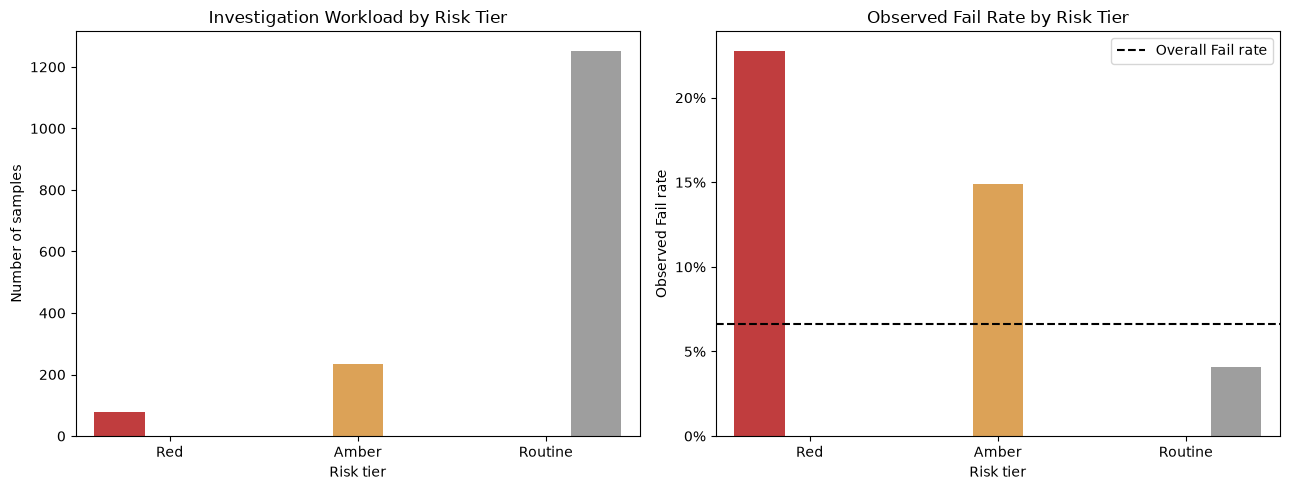

In [24]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

tier_palette = {
    "Red": "#D62728",
    "Amber": "#F2A541",
    "Routine": "#9E9E9E"
}

sns.barplot(
    data=risk_tier_summary,
    x="risk_tier",
    y="sample_count",
    hue="risk_tier",
    palette=tier_palette,
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    "Investigation Workload by Risk Tier"
)

axes[0].set_xlabel(
    "Risk tier"
)

axes[0].set_ylabel(
    "Number of samples"
)

sns.barplot(
    data=risk_tier_summary,
    x="risk_tier",
    y="tier_fail_rate",
    hue="risk_tier",
    palette=tier_palette,
    legend=False,
    ax=axes[1]
)

axes[1].axhline(
    y.mean(),
    color="black",
    linestyle="--",
    label="Overall Fail rate"
)

axes[1].set_title(
    "Observed Fail Rate by Risk Tier"
)

axes[1].set_xlabel(
    "Risk tier"
)

axes[1].set_ylabel(
    "Observed Fail rate"
)

axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, position:
        f"{value:.0%}"
    )
)

axes[1].legend()

plt.tight_layout()
plt.show()

### Interpretation Boundary

The Red and Amber thresholds are retrospective prototype thresholds derived
from out-of-fold scores.

They should not be treated as permanent production specifications because:

1. the Random Forest scores are not calibrated probabilities;
2. the thresholds depend on the score distribution in the current data;
3. a final model trained on all available historical data may produce a
   different score distribution;
4. future process drift may change alert volumes;
5. actual operating thresholds must reflect engineering investigation
   capacity and the cost of missed failures.

In deployment, the thresholds should be re-estimated using the final model
and monitored through alert-volume and outcome feedback.

## 7.13 Attach Candidate Signals to the Investigation Queue

The risk score determines investigation priority. The consensus signals
provide additional context for engineering review.

Two signal groups are used:

1. **direction-consistent signals:** the observed Pass/Fail distribution
   and Logistic Regression coefficient direction agreed;
2. **context-dependent signals:** the univariate distribution direction
   and multivariable Logistic Regression direction disagreed.

The signal-level flags are investigative markers. They are not physical
process specifications or confirmed root-cause alarms.

In [25]:
signal_metadata = pd.DataFrame({
    "feature": [
        "feature_298",
        "feature_21",
        "feature_59",
        "feature_121",
        "feature_163",
        "feature_33",
        "feature_79",
        "feature_122"
    ],
    "signal_tier": [
        "Primary",
        "Primary",
        "Primary",
        "Primary",
        "Primary",
        "Supporting",
        "Supporting",
        "Supporting"
    ],
    "interpretation_type": [
        "Direction-consistent",
        "Direction-consistent",
        "Direction-consistent",
        "Direction-consistent",
        "Context-dependent",
        "Direction-consistent",
        "Context-dependent",
        "Context-dependent"
    ],
    "descriptive_direction": [
        "Positive",
        "Positive",
        "Positive",
        "Positive",
        "Positive",
        "Positive",
        "Positive",
        "Negative"
    ],
    "logistic_direction": [
        "Positive",
        "Positive",
        "Positive",
        "Positive",
        "Negative",
        "Positive",
        "Negative",
        "Positive"
    ]
})

signal_metadata

,feature,signal_tier,interpretation_type,descriptive_direction,logistic_direction
0,feature_298,Primary,Direction-consistent,Positive,Positive
1,feature_21,Primary,Direction-consistent,Positive,Positive
2,feature_59,Primary,Direction-consistent,Positive,Positive
3,feature_121,Primary,Direction-consistent,Positive,Positive
4,feature_163,Primary,Context-dependent,Positive,Negative
5,feature_33,Supporting,Direction-consistent,Positive,Positive
6,feature_79,Supporting,Context-dependent,Positive,Negative
7,feature_122,Supporting,Context-dependent,Negative,Positive


## 7.14 Build a Historical Pass Reference

Confirmed Pass samples are used to construct a retrospective reference
distribution for the eight consensus signals.

For direction-consistent positive signals, the 90th percentile of the
Pass distribution is used as an elevated-value investigation marker.

For context-dependent signals, values below the 5th percentile or above
the 95th percentile of the Pass distribution are marked as unusual,
without assigning a simple high-risk or low-risk direction.

These percentile boundaries are exploratory monitoring markers rather
than engineering specification limits.

In [26]:
candidate_signals = (
    signal_metadata[
        "feature"
    ].tolist()
)

pass_reference_data = X.loc[
    y == 0,
    candidate_signals
]

In [27]:
signal_reference_rows = []

for feature in candidate_signals:

    pass_values = (
        pass_reference_data[
            feature
        ].dropna()
    )

    signal_reference_rows.append({
        "feature": feature,
        "pass_observed_count": (
            len(pass_values)
        ),
        "pass_median": (
            pass_values.median()
        ),
        "pass_q05": (
            pass_values.quantile(0.05)
        ),
        "pass_q10": (
            pass_values.quantile(0.10)
        ),
        "pass_q90": (
            pass_values.quantile(0.90)
        ),
        "pass_q95": (
            pass_values.quantile(0.95)
        )
    })

signal_reference = pd.DataFrame(
    signal_reference_rows
)

In [28]:
signal_reference = (
    signal_reference
    .merge(
        signal_metadata,
        on="feature",
        how="left"
    )
)

signal_reference.round(4)

,feature,pass_observed_count,pass_median,pass_q05,pass_q10,pass_q90,pass_q95,signal_tier,interpretation_type,descriptive_direction,logistic_direction
0,feature_298,1462,0.0522,0.0243,0.0298,0.0866,0.0978,Primary,Direction-consistent,Positive,Positive
1,feature_21,1462,-5529.0000,-6480.4875,-6418.2000,-5207.2500,-5085.7500,Primary,Direction-consistent,Positive,Positive
2,feature_59,1456,0.7223,-6.0478,-4.4864,14.0082,22.7472,Primary,Direction-consistent,Positive,Positive
3,feature_121,1454,15.7900,15.6200,15.6900,15.9300,15.9500,Primary,Direction-consistent,Positive,Positive
4,feature_163,1462,0.1190,0.0540,0.0670,0.1939,0.2230,Primary,Context-dependent,Positive,Negative
5,feature_33,1462,8.7662,8.2832,8.3331,9.3851,9.7137,Supporting,Direction-consistent,Positive,Positive
6,feature_79,1439,0.0000,-0.0294,-0.0222,0.0296,0.0497,Supporting,Context-dependent,Positive,Negative
7,feature_122,1454,3.8820,2.7230,2.8970,4.9200,5.9752,Supporting,Context-dependent,Negative,Positive


In [30]:
for feature in candidate_signals:

    monitoring_data[
        f"{feature}_value"
    ] = X[feature].to_numpy()

In [31]:
direction_consistent_signals = (
    signal_metadata
    .loc[
        signal_metadata[
            "interpretation_type"
        ] == "Direction-consistent",
        "feature"
    ]
    .tolist()
)

direction_consistent_signals

['feature_298', 'feature_21', 'feature_59', 'feature_121', 'feature_33']

In [32]:
for feature in direction_consistent_signals:

    upper_reference = (
        signal_reference
        .loc[
            signal_reference[
                "feature"
            ] == feature,
            "pass_q90"
        ]
        .iloc[0]
    )

    feature_values = (
        monitoring_data[
            f"{feature}_value"
        ]
    )

    monitoring_data[
        f"{feature}_status"
    ] = np.select(
        [
            feature_values.isna(),
            feature_values > upper_reference
        ],
        [
            "Missing",
            "Elevated"
        ],
        default="Within reference"
    )

In [33]:
context_dependent_signals = (
    signal_metadata
    .loc[
        signal_metadata[
            "interpretation_type"
        ] == "Context-dependent",
        "feature"
    ]
    .tolist()
)

context_dependent_signals

['feature_163', 'feature_79', 'feature_122']

In [34]:
for feature in context_dependent_signals:

    lower_reference = (
        signal_reference
        .loc[
            signal_reference[
                "feature"
            ] == feature,
            "pass_q05"
        ]
        .iloc[0]
    )

    upper_reference = (
        signal_reference
        .loc[
            signal_reference[
                "feature"
            ] == feature,
            "pass_q95"
        ]
        .iloc[0]
    )

    feature_values = (
        monitoring_data[
            f"{feature}_value"
        ]
    )

    monitoring_data[
        f"{feature}_status"
    ] = np.select(
        [
            feature_values.isna(),
            feature_values < lower_reference,
            feature_values > upper_reference
        ],
        [
            "Missing",
            "Unusually low",
            "Unusually high"
        ],
        default="Within reference"
    )

In [35]:
direction_status_columns = [
    f"{feature}_status"
    for feature in direction_consistent_signals
]

monitoring_data[
    "elevated_directional_signal_count"
] = (
    monitoring_data[
        direction_status_columns
    ]
    .eq("Elevated")
    .sum(axis=1)
)

In [36]:
context_status_columns = [
    f"{feature}_status"
    for feature in context_dependent_signals
]

monitoring_data[
    "unusual_context_signal_count"
] = (
    ~monitoring_data[
        context_status_columns
    ].isin([
        "Within reference",
        "Missing"
    ])
).sum(axis=1)

In [37]:
all_status_columns = [
    f"{feature}_status"
    for feature in candidate_signals
]

monitoring_data[
    "missing_candidate_signal_count"
] = (
    monitoring_data[
        all_status_columns
    ]
    .eq("Missing")
    .sum(axis=1)
)

In [38]:
def build_signal_summary(row):

    flagged_signals = []

    for feature in candidate_signals:

        status = row[
            f"{feature}_status"
        ]

        if status != "Within reference":

            flagged_signals.append(
                f"{feature}: {status}"
            )

    if len(flagged_signals) == 0:
        return "No candidate-signal flag"

    return "; ".join(
        flagged_signals
    )

In [39]:
monitoring_data[
    "candidate_signal_summary"
] = monitoring_data.apply(
    build_signal_summary,
    axis=1
)

In [40]:
monitoring_data[
    "recommended_action"
] = np.select(
    [
        monitoring_data[
            "risk_tier"
        ] == "Red",

        monitoring_data[
            "risk_tier"
        ] == "Amber"
    ],
    [
        (
            "Priority engineering review; "
            "inspect candidate-signal flags "
            "and available process context"
        ),
        (
            "Secondary review when capacity permits; "
            "check for repeated batch or temporal patterns"
        )
    ],
    default=(
        "Continue existing quality-control workflow; "
        "do not interpret as guaranteed Pass"
    )
)

In [41]:
retrospective_investigation_table = (
    monitoring_data[
        [
            "sample_id",
            "timestamp",
            "risk_tier",
            "risk_rank",
            "risk_percentile",
            "oof_risk_score",
            "actual_outcome",
            "elevated_directional_signal_count",
            "unusual_context_signal_count",
            "missing_candidate_signal_count",
            "candidate_signal_summary",
            "recommended_action"
        ]
    ]
    .sort_values(
        [
            "risk_tier",
            "oof_risk_score"
        ],
        ascending=[
            True,
            False
        ]
    )
)

In [42]:
retrospective_investigation_table.head(
    20
)

,sample_id,timestamp,risk_tier,risk_rank,risk_percentile,oof_risk_score,actual_outcome,elevated_directional_signal_count,unusual_context_signal_count,missing_candidate_signal_count,candidate_signal_summary,recommended_action
34,34,2008-07-28 03:31:00,Red,1,1.000000,0.470654,Pass,1,2,0,feature_59: Elevated; feature_79: Unusually hi...,Priority engineering review; inspect candidate...
47,47,2008-07-29 15:41:00,Red,2,0.999362,0.468713,Pass,3,1,0,feature_298: Elevated; feature_21: Elevated; f...,Priority engineering review; inspect candidate...
161,161,2008-08-08 21:53:00,Red,3,0.998724,0.458976,Pass,0,0,0,No candidate-signal flag,Priority engineering review; inspect candidate...
44,44,2008-07-29 06:19:00,Red,4,0.998086,0.458975,Pass,2,1,0,feature_298: Elevated; feature_21: Elevated; f...,Priority engineering review; inspect candidate...
186,186,2008-08-10 15:59:00,Red,5,0.997447,0.456670,Fail,2,2,0,feature_298: Elevated; feature_21: Elevated; f...,Priority engineering review; inspect candidate...
55,55,2008-07-30 07:08:00,Red,6,0.996809,0.449039,Pass,1,0,0,feature_59: Elevated,Priority engineering review; inspect candidate...
207,207,2008-08-15 18:19:00,Red,7,0.996171,0.448969,Pass,1,0,0,feature_59: Elevated,Priority engineering review; inspect candidate...
209,209,2008-08-15 20:00:00,Red,8,0.995533,0.445976,Pass,1,0,0,feature_59: Elevated,Priority engineering review; inspect candidate...
159,159,2008-08-08 20:21:00,Red,9,0.994895,0.437200,Pass,0,0,0,No candidate-signal flag,Priority engineering review; inspect candidate...
14,14,2008-07-21 11:53:00,Red,10,0.994257,0.434757,Fail,3,2,0,feature_298: Elevated; feature_21: Elevated; f...,Priority engineering review; inspect candidate...


In [43]:
operational_queue_preview = (
    retrospective_investigation_table
    .drop(
        columns=[
            "actual_outcome"
        ]
    )
)

operational_queue_preview.head(
    20
)

,sample_id,timestamp,risk_tier,risk_rank,risk_percentile,oof_risk_score,elevated_directional_signal_count,unusual_context_signal_count,missing_candidate_signal_count,candidate_signal_summary,recommended_action
34,34,2008-07-28 03:31:00,Red,1,1.000000,0.470654,1,2,0,feature_59: Elevated; feature_79: Unusually hi...,Priority engineering review; inspect candidate...
47,47,2008-07-29 15:41:00,Red,2,0.999362,0.468713,3,1,0,feature_298: Elevated; feature_21: Elevated; f...,Priority engineering review; inspect candidate...
161,161,2008-08-08 21:53:00,Red,3,0.998724,0.458976,0,0,0,No candidate-signal flag,Priority engineering review; inspect candidate...
44,44,2008-07-29 06:19:00,Red,4,0.998086,0.458975,2,1,0,feature_298: Elevated; feature_21: Elevated; f...,Priority engineering review; inspect candidate...
186,186,2008-08-10 15:59:00,Red,5,0.997447,0.456670,2,2,0,feature_298: Elevated; feature_21: Elevated; f...,Priority engineering review; inspect candidate...
55,55,2008-07-30 07:08:00,Red,6,0.996809,0.449039,1,0,0,feature_59: Elevated,Priority engineering review; inspect candidate...
207,207,2008-08-15 18:19:00,Red,7,0.996171,0.448969,1,0,0,feature_59: Elevated,Priority engineering review; inspect candidate...
209,209,2008-08-15 20:00:00,Red,8,0.995533,0.445976,1,0,0,feature_59: Elevated,Priority engineering review; inspect candidate...
159,159,2008-08-08 20:21:00,Red,9,0.994895,0.437200,0,0,0,No candidate-signal flag,Priority engineering review; inspect candidate...
14,14,2008-07-21 11:53:00,Red,10,0.994257,0.434757,3,2,0,feature_298: Elevated; feature_21: Elevated; f...,Priority engineering review; inspect candidate...


In [44]:
def get_sample_signal_detail(
    sample_id
):

    sample_position = int(
        sample_id
    )

    detail_rows = []

    for feature in candidate_signals:

        metadata_row = (
            signal_metadata
            .loc[
                signal_metadata[
                    "feature"
                ] == feature
            ]
            .iloc[0]
        )

        reference_row = (
            signal_reference
            .loc[
                signal_reference[
                    "feature"
                ] == feature
            ]
            .iloc[0]
        )

        detail_rows.append({
            "sample_id": sample_position,
            "feature": feature,
            "signal_tier": (
                metadata_row[
                    "signal_tier"
                ]
            ),
            "interpretation_type": (
                metadata_row[
                    "interpretation_type"
                ]
            ),
            "sample_value": (
                monitoring_data
                .loc[
                    monitoring_data[
                        "sample_id"
                    ] == sample_position,
                    f"{feature}_value"
                ]
                .iloc[0]
            ),
            "pass_median": (
                reference_row[
                    "pass_median"
                ]
            ),
            "pass_q05": (
                reference_row[
                    "pass_q05"
                ]
            ),
            "pass_q90": (
                reference_row[
                    "pass_q90"
                ]
            ),
            "pass_q95": (
                reference_row[
                    "pass_q95"
                ]
            ),
            "signal_status": (
                monitoring_data
                .loc[
                    monitoring_data[
                        "sample_id"
                    ] == sample_position,
                    f"{feature}_status"
                ]
                .iloc[0]
            )
        })

    return pd.DataFrame(
        detail_rows
    )

In [45]:
get_sample_signal_detail(
    34
).round(4)

,sample_id,feature,signal_tier,interpretation_type,sample_value,pass_median,pass_q05,pass_q90,pass_q95,signal_status
0,34,feature_298,Primary,Direction-consistent,0.0248,0.0522,0.0243,0.0866,0.0978,Within reference
1,34,feature_21,Primary,Direction-consistent,-6010.2500,-5529.0000,-6480.4875,-5207.2500,-5085.7500,Within reference
2,34,feature_59,Primary,Direction-consistent,17.5473,0.7223,-6.0478,14.0082,22.7472,Elevated
3,34,feature_121,Primary,Direction-consistent,15.9300,15.7900,15.6200,15.9300,15.9500,Within reference
4,34,feature_163,Primary,Context-dependent,0.0600,0.1190,0.0540,0.1939,0.2230,Within reference
5,34,feature_33,Supporting,Direction-consistent,8.9336,8.7662,8.2832,9.3851,9.7137,Within reference
6,34,feature_79,Supporting,Context-dependent,0.0543,0.0000,-0.0294,0.0296,0.0497,Unusually high
7,34,feature_122,Supporting,Context-dependent,2.6470,3.8820,2.7230,4.9200,5.9752,Unusually low


## 7.24 Candidate-Signal Flags across Risk Tiers

The number of candidate-signal flags is summarized across the Red, Amber,
and Routine queues.

This analysis checks whether higher-risk queues also contain more frequent
deviations from the historical Pass reference.

The signal flags are descriptive investigation markers. They do not
determine the model risk tier and are not treated as local explanations
of the Random Forest score.

In [46]:
risk_tier_signal_summary = (
    monitoring_data
    .groupby(
        "risk_tier",
        observed=False
    )
    .agg(
        sample_count=(
            "sample_id",
            "count"
        ),
        mean_directional_flags=(
            "elevated_directional_signal_count",
            "mean"
        ),
        mean_context_flags=(
            "unusual_context_signal_count",
            "mean"
        ),
        samples_with_directional_flag=(
            "elevated_directional_signal_count",
            lambda values: (values > 0).sum()
        ),
        samples_with_context_flag=(
            "unusual_context_signal_count",
            lambda values: (values > 0).sum()
        ),
        samples_with_missing_signal=(
            "missing_candidate_signal_count",
            lambda values: (values > 0).sum()
        )
    )
    .reset_index()
)

In [47]:
risk_tier_signal_summary[
    "directional_flag_rate"
] = (
    risk_tier_signal_summary[
        "samples_with_directional_flag"
    ]
    / risk_tier_signal_summary[
        "sample_count"
    ]
)

risk_tier_signal_summary[
    "context_flag_rate"
] = (
    risk_tier_signal_summary[
        "samples_with_context_flag"
    ]
    / risk_tier_signal_summary[
        "sample_count"
    ]
)

risk_tier_signal_summary[
    "missing_signal_rate"
] = (
    risk_tier_signal_summary[
        "samples_with_missing_signal"
    ]
    / risk_tier_signal_summary[
        "sample_count"
    ]
)

In [48]:
risk_tier_signal_display = (
    risk_tier_signal_summary.copy()
)

rate_columns = [
    "directional_flag_rate",
    "context_flag_rate",
    "missing_signal_rate"
]

risk_tier_signal_display[
    rate_columns
] = (
    risk_tier_signal_display[
        rate_columns
    ] * 100
)

risk_tier_signal_display.round({
    "mean_directional_flags": 2,
    "mean_context_flags": 2,
    "directional_flag_rate": 1,
    "context_flag_rate": 1,
    "missing_signal_rate": 1
})

,risk_tier,sample_count,mean_directional_flags,mean_context_flags,samples_with_directional_flag,samples_with_context_flag,samples_with_missing_signal,directional_flag_rate,context_flag_rate,missing_signal_rate
0,Red,79,1.30,0.63,63,38,0,79.7,48.1,0.0
1,Amber,235,0.89,0.37,157,77,6,66.8,32.8,2.6
2,Routine,1253,0.40,0.27,434,313,34,34.6,25.0,2.7


In [49]:
signal_flag_rows = []

for feature in candidate_signals:

    feature_status = (
        monitoring_data[
            f"{feature}_status"
        ]
    )

    feature_flagged = ~feature_status.isin([
        "Within reference",
        "Missing"
    ])

    temporary_table = pd.DataFrame({
        "risk_tier": (
            monitoring_data[
                "risk_tier"
            ]
        ),
        "feature": feature,
        "flagged": feature_flagged
    })

    feature_summary = (
        temporary_table
        .groupby(
            [
                "risk_tier",
                "feature"
            ],
            observed=False
        )
        .agg(
            flag_rate=(
                "flagged",
                "mean"
            )
        )
        .reset_index()
    )

    signal_flag_rows.append(
        feature_summary
    )

signal_flag_by_tier = pd.concat(
    signal_flag_rows,
    ignore_index=True
)

In [50]:
signal_flag_matrix = (
    signal_flag_by_tier
    .pivot(
        index="feature",
        columns="risk_tier",
        values="flag_rate"
    )
    .reindex(
        index=candidate_signals,
        columns=[
            "Red",
            "Amber",
            "Routine"
        ]
    )
)

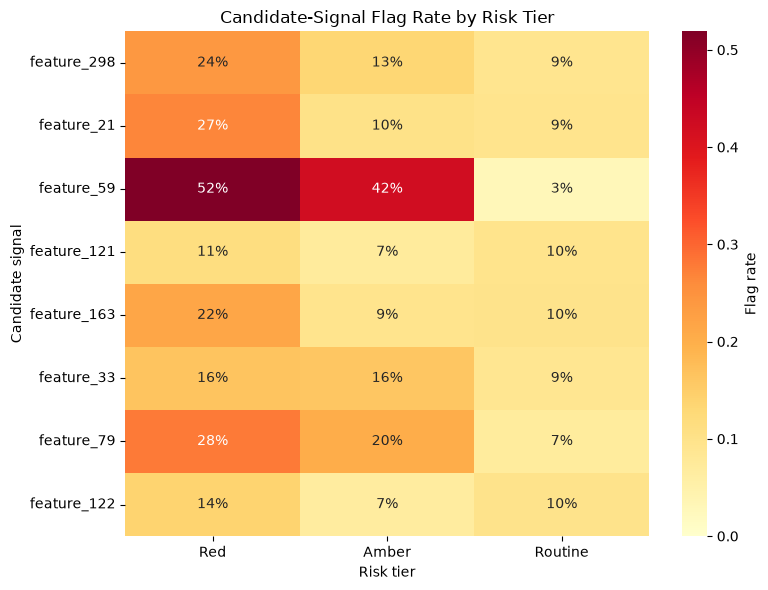

In [51]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    signal_flag_matrix,
    annot=True,
    fmt=".0%",
    cmap="YlOrRd",
    vmin=0,
    vmax=signal_flag_matrix.max().max(),
    cbar_kws={
        "label": "Flag rate"
    }
)

plt.title(
    "Candidate-Signal Flag Rate by Risk Tier"
)

plt.xlabel(
    "Risk tier"
)

plt.ylabel(
    "Candidate signal"
)

plt.tight_layout()
plt.show()

## 7.26 Retrospective Monitoring over Time

The samples are aggregated by calendar week to examine whether model risk,
alert volume, and observed Fail outcomes were concentrated in particular
time periods.

Because the risk scores were generated using shuffled cross-validation,
this is a retrospective monitoring illustration rather than a strict
past-to-future deployment backtest.

In [52]:
monitoring_data[
    "calendar_week"
] = (
    monitoring_data[
        "timestamp"
    ]
    .dt.to_period("W")
    .dt.start_time
)

In [53]:
monitoring_data[
    "is_red"
] = (
    monitoring_data[
        "risk_tier"
    ] == "Red"
).astype(int)

monitoring_data[
    "is_priority_queue"
] = (
    monitoring_data[
        "risk_tier"
    ].isin([
        "Red",
        "Amber"
    ])
).astype(int)

In [54]:
weekly_monitoring = (
    monitoring_data
    .groupby(
        "calendar_week"
    )
    .agg(
        sample_count=(
            "sample_id",
            "count"
        ),
        fail_count=(
            "actual_label",
            "sum"
        ),
        red_count=(
            "is_red",
            "sum"
        ),
        priority_queue_count=(
            "is_priority_queue",
            "sum"
        ),
        mean_risk_score=(
            "oof_risk_score",
            "mean"
        ),
        median_risk_score=(
            "oof_risk_score",
            "median"
        ),
        mean_directional_flags=(
            "elevated_directional_signal_count",
            "mean"
        ),
        mean_context_flags=(
            "unusual_context_signal_count",
            "mean"
        )
    )
    .reset_index()
)

In [55]:
weekly_monitoring[
    "observed_fail_rate"
] = (
    weekly_monitoring[
        "fail_count"
    ]
    / weekly_monitoring[
        "sample_count"
    ]
)

weekly_monitoring[
    "red_alert_rate"
] = (
    weekly_monitoring[
        "red_count"
    ]
    / weekly_monitoring[
        "sample_count"
    ]
)

weekly_monitoring[
    "priority_queue_rate"
] = (
    weekly_monitoring[
        "priority_queue_count"
    ]
    / weekly_monitoring[
        "sample_count"
    ]
)

In [56]:
weekly_monitoring_display = (
    weekly_monitoring.copy()
)

weekly_monitoring_display[
    [
        "observed_fail_rate",
        "red_alert_rate",
        "priority_queue_rate"
    ]
] *= 100

weekly_monitoring_display.round({
    "mean_risk_score": 4,
    "median_risk_score": 4,
    "mean_directional_flags": 2,
    "mean_context_flags": 2,
    "observed_fail_rate": 1,
    "red_alert_rate": 1,
    "priority_queue_rate": 1
})

,calendar_week,sample_count,fail_count,red_count,priority_queue_count,mean_risk_score,median_risk_score,mean_directional_flags,mean_context_flags,observed_fail_rate,red_alert_rate,priority_queue_rate
0,2008-07-14,13,3,3,12,0.3179,0.3043,1.38,1.00,23.1,23.1,92.3
1,2008-07-21,21,2,5,13,0.2907,0.2927,1.38,1.19,9.5,23.8,61.9
2,2008-07-28,48,10,15,38,0.3235,0.3121,1.33,0.81,20.8,31.2,79.2
3,2008-08-04,108,14,19,75,0.2977,0.2867,0.91,0.47,13.0,17.6,69.4
4,2008-08-11,51,7,16,35,0.3152,0.3097,0.71,0.27,13.7,31.4,68.6
5,2008-08-18,208,22,17,93,0.2628,0.2594,0.57,0.15,10.6,8.2,44.7
6,2008-08-25,169,7,1,13,0.2044,0.1970,0.45,0.10,4.1,0.6,7.7
7,2008-09-01,133,2,1,5,0.1837,0.1806,0.49,0.12,1.5,0.8,3.8
8,2008-09-08,95,4,0,2,0.1725,0.1685,0.36,0.25,4.2,0.0,2.1
9,2008-09-15,154,5,0,3,0.1525,0.1425,0.24,0.55,3.2,0.0,1.9


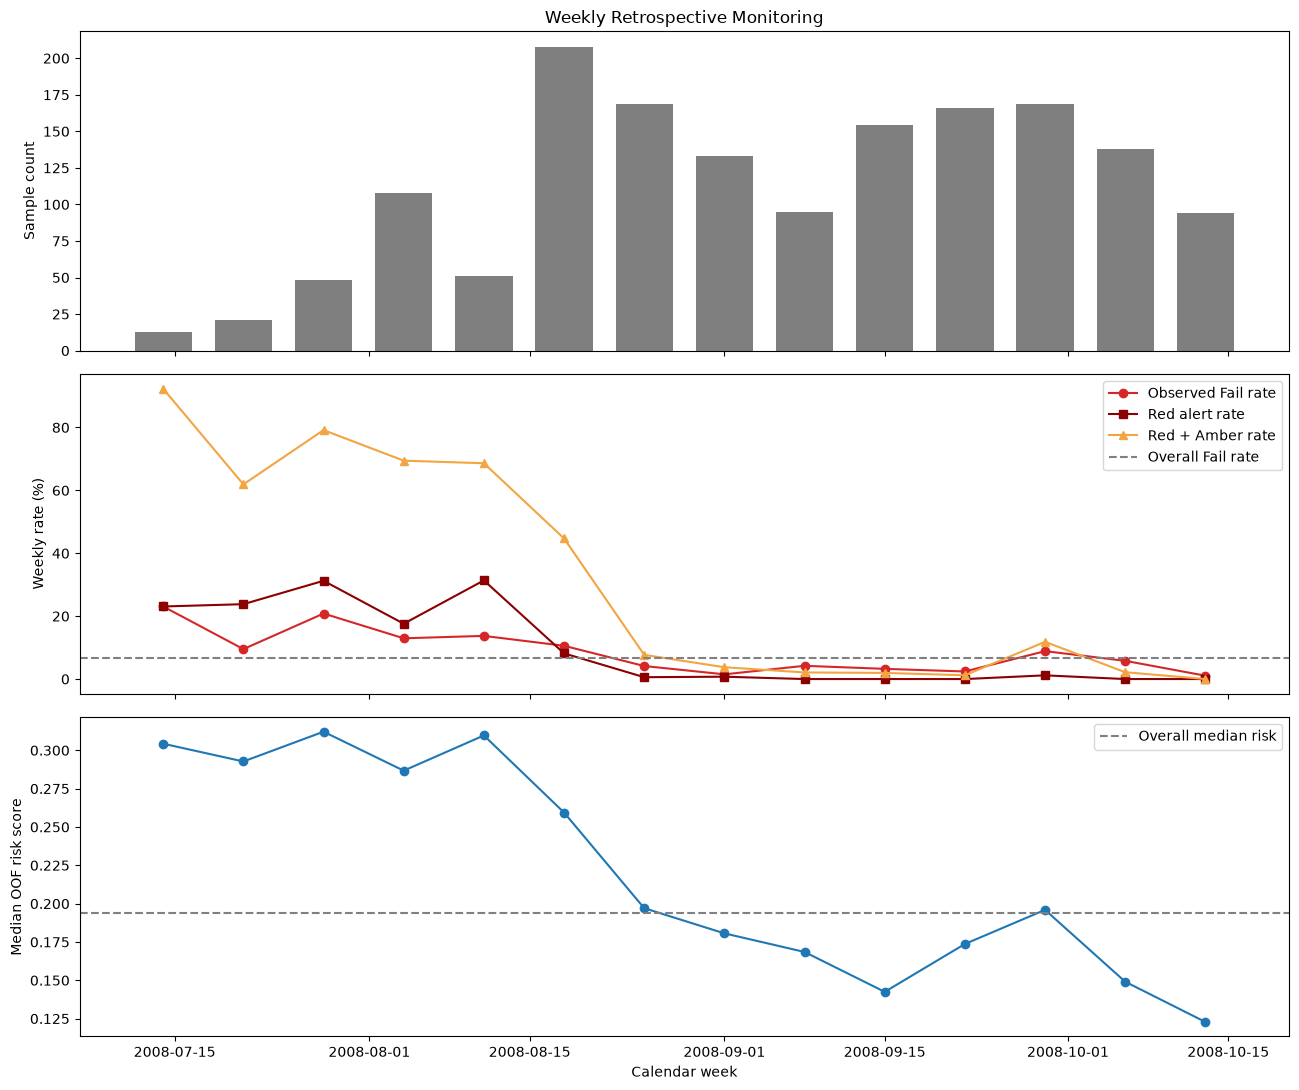

In [57]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(13, 11),
    sharex=True
)

axes[0].bar(
    weekly_monitoring[
        "calendar_week"
    ],
    weekly_monitoring[
        "sample_count"
    ],
    width=5,
    color="#7F7F7F"
)

axes[0].set_ylabel(
    "Sample count"
)

axes[0].set_title(
    "Weekly Retrospective Monitoring"
)

axes[1].plot(
    weekly_monitoring[
        "calendar_week"
    ],
    weekly_monitoring[
        "observed_fail_rate"
    ] * 100,
    marker="o",
    label="Observed Fail rate",
    color="#D62728"
)

axes[1].plot(
    weekly_monitoring[
        "calendar_week"
    ],
    weekly_monitoring[
        "red_alert_rate"
    ] * 100,
    marker="s",
    label="Red alert rate",
    color="#8B0000"
)

axes[1].plot(
    weekly_monitoring[
        "calendar_week"
    ],
    weekly_monitoring[
        "priority_queue_rate"
    ] * 100,
    marker="^",
    label="Red + Amber rate",
    color="#F2A541"
)

axes[1].axhline(
    y.mean() * 100,
    color="gray",
    linestyle="--",
    label="Overall Fail rate"
)

axes[1].set_ylabel(
    "Weekly rate (%)"
)

axes[1].legend()

axes[2].plot(
    weekly_monitoring[
        "calendar_week"
    ],
    weekly_monitoring[
        "median_risk_score"
    ],
    marker="o",
    color="#1F77B4"
)

axes[2].axhline(
    monitoring_data[
        "oof_risk_score"
    ].median(),
    color="gray",
    linestyle="--",
    label="Overall median risk"
)

axes[2].set_ylabel(
    "Median OOF risk score"
)

axes[2].set_xlabel(
    "Calendar week"
)

axes[2].legend()

plt.tight_layout()
plt.show()

## 7.28 Interpretation of Temporal Monitoring

The retrospective monitoring results showed a pronounced temporal shift.

Samples collected from mid-July to mid-August generally had:

- higher median model-risk scores;
- higher Red and Amber alert rates;
- higher observed Fail rates;
- more frequent candidate-signal flags.

From late August onward, the median risk score and alert rates decreased
substantially. Under the global retrospective thresholds, some early weeks
would have assigned most samples to the priority queue, while several
later weeks would have generated few or no Red alerts.

This finding has two operational implications:

1. fixed score thresholds may create unstable investigation workloads;
2. changes in score and alert distributions should be treated as possible
   data or process drift signals rather than only as sample-level alarms.

The available dataset does not contain tool, chamber, lot, recipe, product,
or maintenance metadata. Therefore, the cause of the temporal shift cannot
be identified from this analysis.

In addition, the scores were generated using shuffled cross-validation
rather than strict past-to-future validation. The time plots should be
interpreted as retrospective monitoring illustrations, not deployment
performance estimates.

## 7.29 Proposed Shadow-Mode Evaluation

Before any operational use, the monitoring system should run in shadow
mode.

During shadow mode:

1. the model generates a risk score and risk tier for each new sample;
2. Red and Amber alerts are logged but do not automatically hold, scrap,
   or reclassify products;
3. existing production, testing, and quality-control procedures remain
   unchanged;
4. final Pass/Fail outcomes are linked back to model predictions;
5. engineers record whether each reviewed alert corresponded to a
   meaningful process, equipment, measurement, or data-quality issue;
6. alert volume, investigation workload, data drift, and delayed model
   performance are reviewed periodically.

The shadow-mode period should cover sufficient production volume and Fail
events rather than being judged from only a small number of calendar days.

### Shadow-Mode Logging Requirements

| Category | Fields |
|---|---|
| Sample identity | sample ID, lot ID, wafer ID, product type |
| Time context | measurement time, process time, model-scoring time |
| Equipment context | tool, chamber, recipe, process step |
| Model output | model version, risk score, risk tier, score percentile |
| Signal context | candidate-signal values, missingness, reference flags |
| Engineering action | reviewed or not, review time, investigator |
| Investigation result | confirmed issue, no issue, inconclusive |
| Final outcome | Pass/Fail label and label-availability time |

## 7.30 Monitoring Indicators

### 1. Data-quality indicators

- number of received samples;
- number of missing or invalid required features;
- candidate-signal missing rates;
- schema, unit, or feature-order changes;
- timestamp delays and duplicated sample IDs.

### 2. Score and alert indicators

- median and upper-percentile risk scores;
- Red alert rate;
- Red-plus-Amber priority-queue rate;
- number of alerts relative to investigation capacity;
- sudden concentration of alerts by tool, chamber, lot, or product.

### 3. Delayed outcome-performance indicators

After final labels become available:

- Average Precision;
- Fail recall at the operational investigation budget;
- alert precision;
- false alarms per detected Fail;
- investigations per detected Fail;
- performance by product, tool, chamber, and time period.

### 4. Engineering-value indicators

- proportion of alerts reviewed;
- investigation turnaround time;
- proportion linked to a confirmed issue;
- repeated issues identified across related samples;
- engineering hours per confirmed issue;
- actions taken and recurrence after corrective action.

## 7.31 Alert Governance

The following safeguards are recommended:

1. no product is automatically held or scrapped solely because of the
   model score;
2. thresholds and model versions are recorded and frozen during a formal
   evaluation period;
3. alert-volume spikes trigger a system-level drift investigation;
4. capacity limits are defined before operational use;
5. missing or invalid required data trigger a data-quality warning rather
   than an unsupported risk prediction;
6. final outcomes and engineering findings are linked back to each alert;
7. threshold changes require documented review;
8. model retraining is considered only after sufficient new labeled data
   and evidence of sustained drift.

## 7.32 Proposed Investigation Workflow

### Red tier

- place the sample at the highest investigation priority;
- review available tool, chamber, lot, recipe, and measurement context;
- inspect direction-consistent candidate signals;
- inspect context-dependent signals without assuming a fixed risk
  direction;
- search for related alerts from the same equipment or production group;
- record the investigation outcome.

### Amber tier

- review when investigation capacity permits;
- prioritize repeated Amber patterns within the same lot, tool, chamber,
  or time window;
- escalate repeated or clustered Amber alerts even if individual scores
  do not reach the Red threshold.

### Routine tier

- continue existing quality-control and testing procedures;
- do not interpret the tier as guaranteed Pass;
- retain a sample of Routine cases for auditing;
- review false negatives after final labels become available.

In [58]:
output_dir = Path(
    "../outputs/chapter_07"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [59]:
investigation_budget_table.to_csv(
    output_dir
    / "investigation_budget_table.csv",
    index=False
)

risk_tier_summary.to_csv(
    output_dir
    / "risk_tier_summary.csv",
    index=False
)

signal_reference.to_csv(
    output_dir
    / "candidate_signal_reference.csv",
    index=False
)

retrospective_investigation_table.to_csv(
    output_dir
    / "retrospective_investigation_queue.csv",
    index=False
)

weekly_monitoring.to_csv(
    output_dir
    / "weekly_monitoring_summary.csv",
    index=False
)

In [60]:
sorted(
    path.name
    for path in output_dir.iterdir()
)

['candidate_signal_reference.csv',
 'investigation_budget_table.csv',
 'retrospective_investigation_queue.csv',
 'risk_tier_summary.csv',
 'weekly_monitoring_summary.csv']

## 7.33 Conclusions

The out-of-fold Random Forest scores were translated into a retrospective
three-level investigation queue.

The Red tier contained the highest-risk 5% of samples. Its observed Fail
rate was 22.8%, approximately 3.43 times the overall Fail rate. The Amber
tier contained the next 15% of samples and had an observed Fail rate of
14.9%. Together, the Red and Amber queues represented 20% of the samples
and contained 51% of all observed Fail cases.

The Routine tier had a lower observed Fail rate of 4.1%, but it still
contained 49% of all Fail cases. Therefore, the model should supplement
rather than replace existing production testing and quality-control
procedures.

Candidate-signal flags were more frequent in higher-risk tiers. At least
one direction-consistent signal was elevated in 79.7% of Red samples,
66.8% of Amber samples, and 34.6% of Routine samples. Feature_59 showed
the clearest tier separation, with flag rates of 52%, 42%, and 3% in the
Red, Amber, and Routine tiers, respectively.

The candidate-signal flags provide investigation context but are not local
explanations of individual Random Forest predictions. The model used all
590 measurement variables and could also rely on nonlinear relationships,
interactions, and variables outside the final consensus-signal list.

Retrospective weekly monitoring revealed a pronounced temporal shift.
Risk scores, priority-queue rates, observed Fail rates, and candidate-
signal flags were generally higher during the earlier part of the data
period and lower during the later period. As a result, global fixed score
thresholds would have produced unstable weekly investigation workloads.

A real implementation should therefore begin in shadow mode. Model scores
and alerts should be logged without automatically changing product
disposition. Alert volume, data quality, score distributions, delayed
outcome performance, and engineering investigation value should be
monitored over time.

The proposed monitoring system is an investigation-prioritization and
decision-support framework. It is not an automatic product-disposition
system, and the anonymous candidate signals are not confirmed physical
root causes.